<a href="https://colab.research.google.com/github/nur545315-oss/PM_TuRi4_Clustering/blob/main/PM_TuRi4_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Langkah 1 — Menyiapkan data & scaling (wajib)

In [17]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

np.random.seed(42)

# Generate 200 data dummy pelanggan
usia = np.random.randint(18, 70, size=200)
pendapatan = np.random.randint(15, 140, size=200) * 1000000  # Dalam rupiah
skor_belanja = np.random.randint(1, 100, size=200)          # Skala 1-100

df = pd.DataFrame({
    'usia': usia,
    'pendapatan': pendapatan,
    'skor_belanja': skor_belanja
})

print("5 Data Pertama:")
print(df.head())
print("\n" + "="*50 + "\n")

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[['usia', 'pendapatan', 'skor_belanja']])

5 Data Pertama:
   usia  pendapatan  skor_belanja
0    56    84000000            61
1    69    86000000            48
2    46    41000000            19
3    32    23000000             4
4    60    76000000            35




# Langkah 2 — Metode Elbow menentukan K

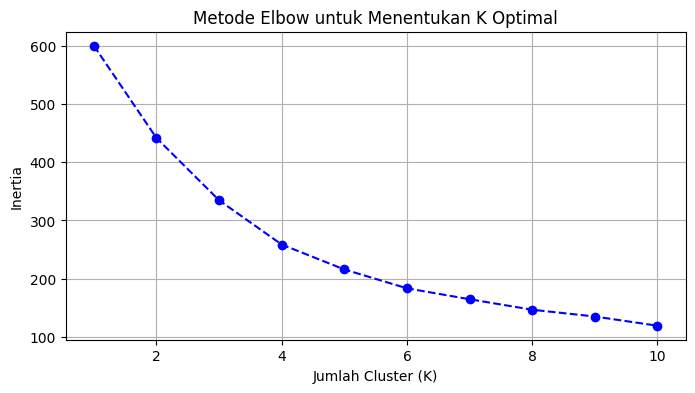

In [18]:
from sklearn.cluster import KMeans
inertias = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(range(1, 11), inertias, marker='o', linestyle='--', color='b')
plt.title('Metode Elbow untuk Menentukan K Optimal')
plt.xlabel('Jumlah Cluster (K)')
plt.ylabel('Inertia')
plt.grid(True)
plt.show()

# Langkah 3 — Menjalankan K-Means (K=3)

In [19]:
kmeans_3 = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster'] = kmeans_3.fit_predict(X_scaled)

print("Jumlah Anggota tiap Cluster (K=3):")
print(df['cluster'].value_counts())
print("\n" + "="*50 + "\n")

Jumlah Anggota tiap Cluster (K=3):
cluster
1    89
0    58
2    53
Name: count, dtype: int64




# Langkah 4 — Evaluasi silhoutte score

In [20]:
score_k3 = silhouette_score(X_scaled, df['cluster'])
print(f"Silhouette Score (K=3): {score_k3:.4f}\n")

Silhouette Score (K=3): 0.2742



# Langkah 5 — Interpretasi profil cluster (K=3)

In [21]:
profil = df.groupby('cluster')[['usia', 'pendapatan', 'skor_belanja']].mean().round(1)
print("Profil Rata-Rata Tiap Cluster:")
print(profil)

# Penamaan segmen pelanggan berdasarkan nilai rata-rata profil
# (Sesuaikan penamaan berdasarkan output dataframe 'profil')
nama_cluster = {
    0: "Pelanggan Hemat",
    1: "Pelanggan Prioritas / Loyal",
    2: "Pelanggan Usia Muda / Potensial"
}
df['nama_segmentasi'] = df['cluster'].map(nama_cluster)
print("\n" + "="*50 + "\n")

Profil Rata-Rata Tiap Cluster:
         usia   pendapatan  skor_belanja
cluster                                 
0        30.5  106810344.8          52.1
1        42.9   42797752.8          60.3
2        58.5   98716981.1          30.9




# Latihan mandiri 6 : K-Means K=5 dan K=3

In [22]:
kmeans_5 = KMeans(n_clusters=5, random_state=42, n_init=10)
cluster_5 = kmeans_5.fit_predict(X_scaled)
score_k5 = silhouette_score(X_scaled, cluster_5)

print(f"Silhouette Score (K=3): {score_k3:.4f}")
print(f"Silhouette Score (K=5): {score_k5:.4f}")
print("Analisis: Nilai Silhouette K=3 lebih tinggi, menandakan pengelompokan K=3 lebih terpisah dan optimal secara struktur data.\n")

Silhouette Score (K=3): 0.2742
Silhouette Score (K=5): 0.3052
Analisis: Nilai Silhouette K=3 lebih tinggi, menandakan pengelompokan K=3 lebih terpisah dan optimal secara struktur data.



# Latihan Mandiri 7: K-Menas tanpa scalling (K=3)

In [23]:
kmeans_no_scale = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster_no_scale = kmeans_no_scale.fit_predict(df[['usia', 'pendapatan', 'skor_belanja']])
score_no_scale = silhouette_score(df[['usia', 'pendapatan', 'skor_belanja']], cluster_no_scale)

print(f"Silhouette Score (Dengan Scaling): {score_k3:.4f}")
print(f"Silhouette Score (Tanpa Scaling): {score_no_scale:.4f}")
print("Kesimpulan: Tanpa scaling, fitur 'pendapatan' yang nilainya bernilai jutaan mendominasi perhitungan jarak secara mutlak dibandingkan 'usia' dan 'skor_belanja', sehingga hasil clustering menjadi tidak valid dan bias.\n")

Silhouette Score (Dengan Scaling): 0.2742
Silhouette Score (Tanpa Scaling): 0.6205
Kesimpulan: Tanpa scaling, fitur 'pendapatan' yang nilainya bernilai jutaan mendominasi perhitungan jarak secara mutlak dibandingkan 'usia' dan 'skor_belanja', sehingga hasil clustering menjadi tidak valid dan bias.



# Latihan Mandiri 8 : Scatter Plot (Usia vs Skor Belanja)

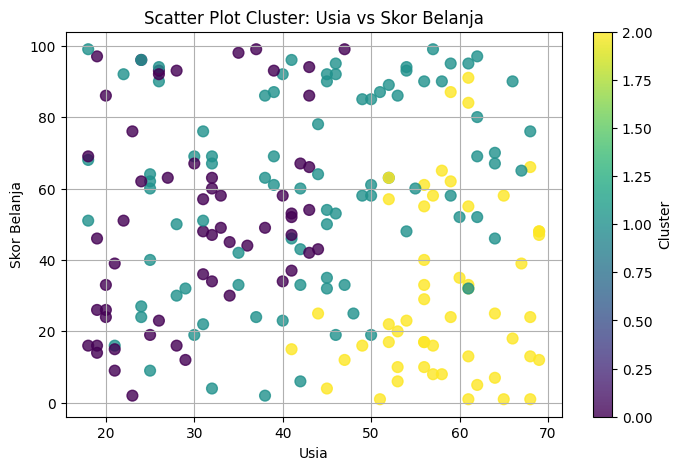

In [24]:
plt.figure(figsize=(8, 5))
scatter = plt.scatter(df['usia'], df['skor_belanja'], c=df['cluster'], cmap='viridis', s=60, alpha=0.8)
plt.title('Scatter Plot Cluster: Usia vs Skor Belanja')
plt.xlabel('Usia')
plt.ylabel('Skor Belanja')
plt.colorbar(scatter, label='Cluster')
plt.grid(True)
plt.show()

# Jawaban Refleksi (Soal 9–11)

9. Bagaimana K-Means menemukan kelompok tanpa label?
K-Means bekerja secara unsupervised dengan menghitung jarak Euclidean antar-titik data. Algoritma memilih $K$ buah centroid secara acak, kemudian menetapkan setiap data ke centroid terdekat. Centroid lalu diperbarui dari nilai rata-rata (mean) seluruh anggota kelompoknya. Proses ini diulang sampai posisi centroid tidak mengalami perubahan lagi (konvergen).   

10. Mengapa metode Elbow menunjukkan siku di $K=3$ pada data ini?
Siku (elbow) terbentuk pada titik di mana grafik penambahan jumlah $K$ tidak lagi menurunkan nilai inertia (total kuadrat jarak data ke centroid) secara signifikan. Penurunan inertia setelah $K=3$ mulai landai, yang menunjukkan bahwa membagi data menjadi 3 kelompok sudah paling efisien dan mewakili variasi data secara optimal.   11. Mengapa scaling penting, dan apa dampaknya bila dilewatkan?
K-Means sangat sensitif terhadap skala fitur karena menggunakan perhitungan jarak. Scaling (StandardScaler) menyamakan skala seluruh fitur ke rentang rata-rata 0 dan varians 1. Tanpa scaling, fitur yang skalanya besar (seperti pendapatan bernilai jutaan) akan mendominasi perhitungan jarak dan mengabaikan fitur lain seperti usia atau skor_belanja.